# Machine Learning Model Evaluation: Classification Metrics and Regression Diagnostics

This assignment has two deliberately separate parts. First, it verifies two small **reference case studies** supplied in course PDFs. Second, it trains and evaluates two independent baseline models using built-in scikit-learn datasets. The PDF examples are not training data, and the trained experiments are not derived from the PDFs.

**Student:** Abrham Geberemedhin  
**Student ID:** WOUR/0082/16  
**GitHub repository:** [abrilohd/ML_Assignments](https://github.com/abrilohd/ML_Assignments)

## Learning objectives

- Explain and calculate the main evaluation metrics for binary classification and regression.
- Distinguish a calculation from supplied predictions from evaluation of a model on held-out data.
- Train reproducible baseline models with proper train/test separation.
- Interpret metrics and diagnostic plots without making unsupported claims.


## 1. Environment, reproducibility, and engineering choices

The notebook uses only NumPy, Pandas, Matplotlib, and scikit-learn. The datasets are bundled with scikit-learn, so no private file, upload, API key, or Windows-specific path is required. The fixed random state makes the train/test splits reproducible.

Preprocessing is included inside scikit-learn pipelines. This is important because any fitted transformation must learn only from the training set; otherwise, information from the held-out test set could leak into training.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.datasets import load_breast_cancer, load_diabetes
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print(f"Working directory: {Path.cwd().name}")
print(f"NumPy: {np.__version__} | Pandas: {pd.__version__} | scikit-learn: {sklearn.__version__}")


Working directory: ML_Assignment
NumPy: 2.4.2 | Pandas: 3.0.0 | scikit-learn: 1.9.1


## 2. Classification theory and metric formulas

For a binary classifier, choose one class as the **positive** class. A confusion matrix records true positives (TP), true negatives (TN), false positives (FP), and false negatives (FN). In the reference email example, spam is positive. In the model-training experiment, malignant is positive so that recall describes the share of malignant observations detected.

\[
\text{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN},\quad
\text{Precision}=\frac{TP}{TP+FP},\quad
\text{Recall}=\frac{TP}{TP+FN}
\]

\[
\text{Specificity}=\frac{TN}{TN+FP},\quad
F1=\frac{2(\text{Precision})(\text{Recall})}{\text{Precision}+\text{Recall}}
\]

Accuracy alone can be misleading when classes are imbalanced or the cost of FP and FN differs. The full confusion matrix and several metrics reveal the type of error being made.


## 3. Classification reference case: step-by-step verification

The supplied PDF evaluates an email filter on 100 emails. It provides counts rather than features or fitted-model predictions: TP = 40, TN = 45, FP = 5, and FN = 10. The following is therefore a **reference calculation**, not model training.


In [2]:
def safe_divide(numerator, denominator):
    # Return NaN for an undefined metric instead of raising a division error.
    return np.nan if denominator == 0 else numerator / denominator


TP, TN, FP, FN = 40, 45, 5, 10
total_emails = TP + TN + FP + FN

if total_emails != 100 or min(TP, TN, FP, FN) < 0:
    raise ValueError("The reference confusion-matrix counts are invalid.")

reference_classification = pd.DataFrame(
    {
        "Metric": ["Accuracy", "Precision", "Recall / sensitivity", "Specificity", "F1-score"],
        "Substitution": [
            "(40 + 45) / 100",
            "40 / (40 + 5)",
            "40 / (40 + 10)",
            "45 / (45 + 5)",
            "2 × (40/45) × (40/50) / ((40/45) + (40/50))",
        ],
        "Value": [
            safe_divide(TP + TN, total_emails),
            safe_divide(TP, TP + FP),
            safe_divide(TP, TP + FN),
            safe_divide(TN, TN + FP),
            safe_divide(2 * safe_divide(TP, TP + FP) * safe_divide(TP, TP + FN),
                        safe_divide(TP, TP + FP) + safe_divide(TP, TP + FN)),
        ],
    }
)
reference_classification["Percent"] = reference_classification["Value"].map(lambda value: f"{value:.2%}")
display(reference_classification)

assert np.allclose(reference_classification["Value"], [0.85, 40 / 45, 0.80, 0.90, 0.8421052632])
print("All classification reference metrics match the supplied counts.")


All classification reference metrics match the supplied counts.


                 Metric                                 Substitution     Value Percent
0              Accuracy                              (40 + 45) / 100  0.850000  85.00%
1             Precision                                40 / (40 + 5)  0.888889  88.89%
2  Recall / sensitivity                               40 / (40 + 10)  0.800000  80.00%
3           Specificity                                45 / (45 + 5)  0.900000  90.00%
4              F1-score  2 × (40/45) × (40/50) / ((40/45) + (40/50))  0.842105  84.21%

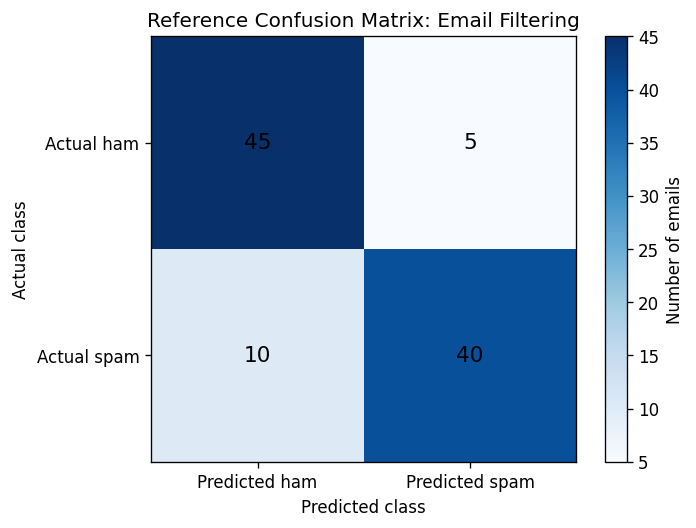

In [3]:
reference_matrix = np.array([[TN, FP], [FN, TP]])

fig, ax = plt.subplots(figsize=(6, 4.5))
image = ax.imshow(reference_matrix, cmap="Blues")
fig.colorbar(image, ax=ax, label="Number of emails")
ax.set(
    xticks=[0, 1],
    yticks=[0, 1],
    xticklabels=["Predicted ham", "Predicted spam"],
    yticklabels=["Actual ham", "Actual spam"],
    xlabel="Predicted class",
    ylabel="Actual class",
    title="Reference Confusion Matrix: Email Filtering",
)
for row in range(2):
    for column in range(2):
        ax.text(column, row, reference_matrix[row, column], ha="center", va="center", fontsize=13)
plt.tight_layout()
plt.show()


The reference accuracy is 85%, but recall is 80%, so 10 of 50 spam emails were missed. Precision is about 88.89%, so most messages predicted as spam actually were spam. Specificity is 90%, meaning 45 of 50 legitimate messages were correctly delivered. The reference set is balanced (50 spam and 50 ham), so it illustrates the metrics but not an observed class-imbalance problem. The source's recommendation to prioritize precision is a policy choice based on assumed costs; this confusion matrix alone cannot establish which error is more harmful in practice.


## 4. Genuine classification experiment: breast cancer dataset

This independent experiment uses scikit-learn's built-in Wisconsin Diagnostic Breast Cancer dataset. It contains 569 observations, 30 numeric features, and two labels. It is used here as a teaching dataset only; this notebook is **not** a clinical diagnostic tool. To make the error types easy to discuss, the target is recoded so `1 = malignant` (positive) and `0 = benign` (negative).


In [4]:
cancer = load_breast_cancer(as_frame=True)
X_classification = cancer.data.copy()
y_classification = (cancer.target == 0).astype(int)  # 1 = malignant, 0 = benign

if X_classification.shape[0] != y_classification.shape[0] or X_classification.isna().any().any():
    raise ValueError("Classification features and target must align and contain no missing values.")
if set(y_classification.unique()) != {0, 1}:
    raise ValueError("The classification target must be binary.")

classification_overview = pd.DataFrame(
    {
        "Item": ["Observations", "Features", "Benign (negative)", "Malignant (positive)"],
        "Value": [
            X_classification.shape[0],
            X_classification.shape[1],
            int((y_classification == 0).sum()),
            int((y_classification == 1).sum()),
        ],
    }
)
display(classification_overview)
display(X_classification.head())


                   Item  Value
0          Observations    569
1              Features     30
2     Benign (negative)    357
3  Malignant (positive)    212

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  mean compactness  mean concavity  mean concave points  mean symmetry  mean fractal dimension  radius error  texture error  perimeter error  area error  smoothness error  compactness error  concavity error  concave points error  symmetry error  fractal dimension error  worst radius  worst texture  worst perimeter  worst area  worst smoothness  worst compactness  worst concavity  worst concave points  worst symmetry  worst fractal dimension
0        17.99         10.38          122.80     1001.0          0.11840           0.27760          0.3001              0.14710         0.2419                 0.07871        1.0950         0.9053            8.589      153.40          0.006399            0.04904          0.05373               0.01587         0.03003                 0.006193         25.38          17.33           184.60      2019.0            0.1622             0.6656           0.7119                0.2654        

In [5]:
X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X_classification,
    y_classification,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y_classification,
)

classification_pipeline = Pipeline(
    steps=[
        ("scale", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ]
)

classification_pipeline.fit(X_train_class, y_train_class)
y_pred_class = classification_pipeline.predict(X_test_class)

if y_pred_class.shape != y_test_class.shape or not set(np.unique(y_pred_class)).issubset({0, 1}):
    raise ValueError("Classification predictions have an unexpected shape or label.")

print(f"Training observations: {X_train_class.shape[0]} | Held-out test observations: {X_test_class.shape[0]}")
print("The scaler is fitted inside the pipeline, using training data only.")


Training observations: 426 | Held-out test observations: 143
The scaler is fitted inside the pipeline, using training data only.


In [6]:
class_matrix = confusion_matrix(y_test_class, y_pred_class, labels=[0, 1])
tn, fp, fn, tp = class_matrix.ravel()

classification_metrics = pd.DataFrame(
    {
        "Metric": ["Accuracy", "Precision (malignant)", "Recall (malignant)", "Specificity (benign)", "F1-score (malignant)"],
        "Value": [
            accuracy_score(y_test_class, y_pred_class),
            safe_divide(tp, tp + fp),
            safe_divide(tp, tp + fn),
            safe_divide(tn, tn + fp),
            safe_divide(
                2 * safe_divide(tp, tp + fp) * safe_divide(tp, tp + fn),
                safe_divide(tp, tp + fp) + safe_divide(tp, tp + fn),
            ),
        ],
    }
)
classification_metrics["Percent"] = classification_metrics["Value"].map(lambda value: f"{value:.2%}")
display(classification_metrics)

# The summary table keeps undefined metrics as NaN; this fallback keeps the
# classification report compatible with older scikit-learn releases.
print(
    classification_report(
        y_test_class,
        y_pred_class,
        target_names=["Benign", "Malignant"],
        zero_division=0,
    )
)


              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        90
   Malignant       0.98      0.92      0.95        53

    accuracy                           0.97       143
   macro avg       0.97      0.96      0.96       143
weighted avg       0.97      0.97      0.96       143



                  Metric     Value Percent
0               Accuracy  0.965035  96.50%
1  Precision (malignant)  0.980000  98.00%
2     Recall (malignant)  0.924528  92.45%
3   Specificity (benign)  0.988889  98.89%
4   F1-score (malignant)  0.951456  95.15%

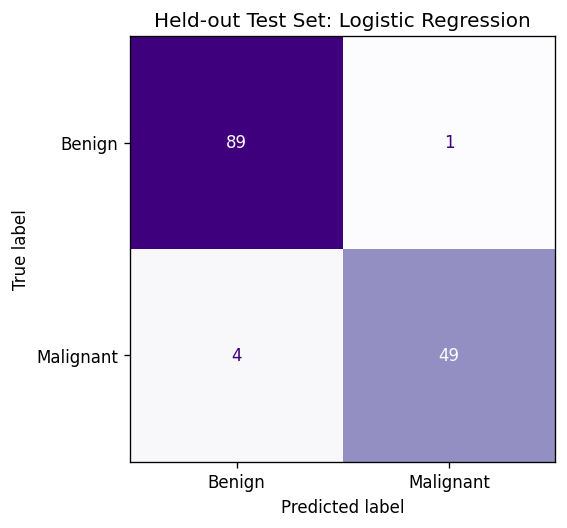

In [7]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ConfusionMatrixDisplay(class_matrix, display_labels=["Benign", "Malignant"]).plot(cmap="Purples", ax=ax, colorbar=False)
ax.set_title("Held-out Test Set: Logistic Regression")
plt.tight_layout()
plt.show()


The metrics above come from predictions on the held-out test set, unlike the PDF reference calculation. Precision, recall, and specificity show different error types. A strong score on this educational dataset does not establish clinical usefulness, fairness, or performance in another population.


## 5. Regression theory and metric formulas

For regression, a residual is defined here as `actual - predicted`. Negative residuals mean over-prediction; positive residuals mean under-prediction.

\[
MAE=\frac{1}{n}\sum|y-\hat{y}|,\quad
MSE=\frac{1}{n}\sum(y-\hat{y})^2,\quad
RMSE=\sqrt{MSE}
\]

\[
R^2=1-\frac{SS_{res}}{SS_{tot}},\quad
SS_{res}=\sum(y-\hat{y})^2,\quad
SS_{tot}=\sum(y-\bar{y})^2
\]

MAE is expressed in the target's units, MSE squares large errors, RMSE returns to the target's units, and R-squared compares error with variation around the target mean.


## 6. Regression reference case: step-by-step verification

The PDF supplies actual and predicted post-operative lengths of stay for five patients. This is a small reference calculation, not a trainable clinical dataset. It must not be interpreted as a validated hospital model.


In [8]:
actual_days = np.array([4.0, 8.0, 3.0, 12.0, 8.0])
predicted_days = np.array([5.0, 7.0, 2.0, 15.0, 9.0])

if actual_days.shape != predicted_days.shape or actual_days.size == 0:
    raise ValueError("Reference regression arrays must be non-empty and have the same shape.")
if not (np.isfinite(actual_days).all() and np.isfinite(predicted_days).all()):
    raise ValueError("Reference regression arrays must contain finite values.")

residuals = actual_days - predicted_days
absolute_errors = np.abs(residuals)
squared_errors = residuals ** 2
mean_actual = actual_days.mean()
ss_res = squared_errors.sum()
ss_tot = ((actual_days - mean_actual) ** 2).sum()

reference_regression_table = pd.DataFrame(
    {
        "Patient": np.arange(1, 6),
        "Actual days": actual_days,
        "Predicted days": predicted_days,
        "Residual (actual - predicted)": residuals,
        "Absolute error": absolute_errors,
        "Squared error": squared_errors,
    }
)
display(reference_regression_table)

reference_regression_metrics = pd.DataFrame(
    {
        "Metric": ["MAE", "MSE", "RMSE", "R-squared"],
        "Substitution": [
            "(1 + 1 + 1 + 3 + 1) / 5",
            "(1 + 1 + 1 + 9 + 1) / 5",
            "sqrt(2.6)",
            "1 - 13 / 52",
        ],
        "Value": [absolute_errors.mean(), squared_errors.mean(), np.sqrt(squared_errors.mean()), 1 - ss_res / ss_tot],
    }
)
display(reference_regression_metrics.style.format({"Value": "{:.4f}"}))

assert np.isclose(ss_res, 13.0)
assert np.isclose(ss_tot, 52.0)
assert np.allclose(reference_regression_metrics["Value"], [1.4, 2.6, np.sqrt(2.6), 0.75])
print("MAE, MSE, and RMSE match the PDF. Verified R-squared is 75.00%.")


MAE, MSE, and RMSE match the PDF. Verified R-squared is 75.00%.


   Patient  Actual days  Predicted days  Residual (actual - predicted)  Absolute error  Squared error
0        1          4.0             5.0                           -1.0             1.0            1.0
1        2          8.0             7.0                            1.0             1.0            1.0
2        3          3.0             2.0                            1.0             1.0            1.0
3        4         12.0            15.0                           -3.0             3.0            9.0
4        5          8.0             9.0                           -1.0             1.0            1.0

      Metric             Substitution     Value
0        MAE  (1 + 1 + 1 + 3 + 1) / 5  1.400000
1        MSE  (1 + 1 + 1 + 9 + 1) / 5  2.600000
2       RMSE                sqrt(2.6)  1.612452
3  R-squared              1 - 13 / 52  0.750000

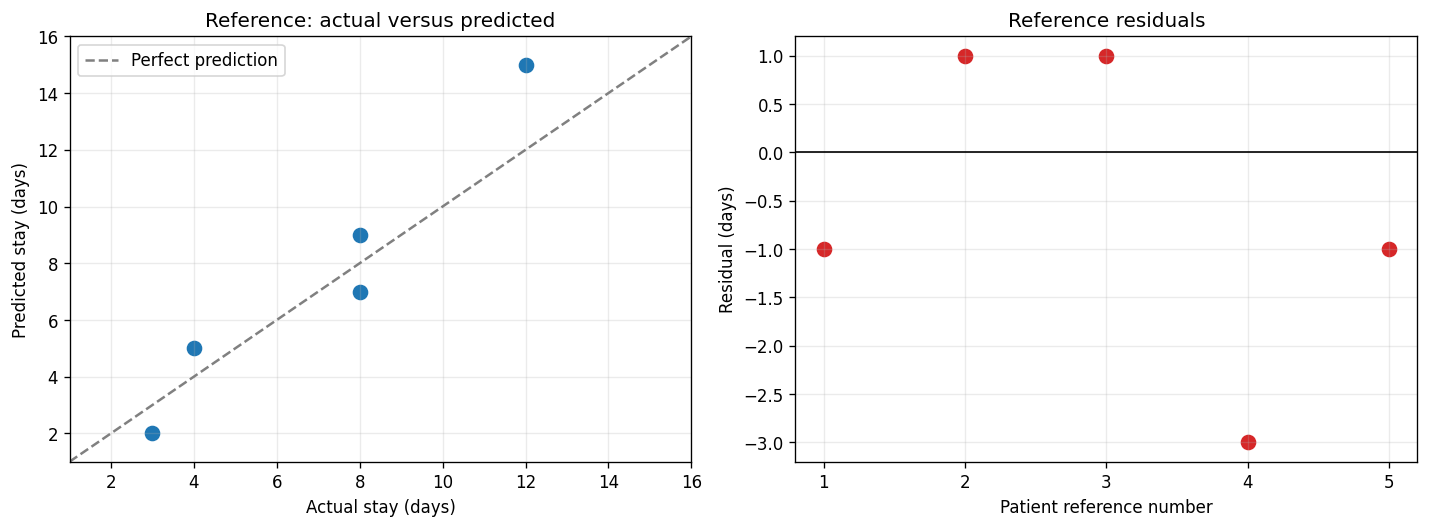

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

limits = [min(actual_days.min(), predicted_days.min()) - 1, max(actual_days.max(), predicted_days.max()) + 1]
axes[0].scatter(actual_days, predicted_days, s=70, color="#1f77b4")
axes[0].plot(limits, limits, "--", color="gray", label="Perfect prediction")
axes[0].set(xlim=limits, ylim=limits, xlabel="Actual stay (days)", ylabel="Predicted stay (days)", title="Reference: actual versus predicted")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].axhline(0, color="black", linewidth=1)
axes[1].scatter(np.arange(1, 6), residuals, s=70, color="#d62728")
axes[1].set(xticks=np.arange(1, 6), xlabel="Patient reference number", ylabel="Residual (days)", title="Reference residuals")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()


The PDF reports R-squared = 75.93% using \(SS_{tot}=54\). However, the listed actual values have mean 7 and squared deviations \(9, 1, 16, 25, 1\), which sum to **52**. With \(SS_{res}=13\), the verified calculation is \(1 - 13/52 = 0.75\), or **75.00%**. The reported 75.93% results from dividing 13 by 54, but 54 is inconsistent with the displayed observations. The document's operational claims are not established by five observations and supplied predictions; these values support only a small reference calculation, not a validated clinical or operational conclusion.


## 7. Genuine regression experiment: diabetes dataset

This independent experiment uses scikit-learn's built-in diabetes regression dataset (442 observations, 10 standardized baseline features, and a quantitative target measured one year after baseline). It is not the patient length-of-stay example from the PDF and must not be used to make medical or operational claims.


In [10]:
diabetes = load_diabetes(as_frame=True)
X_regression = diabetes.data.copy()
y_regression = diabetes.target.copy()

if X_regression.shape[0] != y_regression.shape[0] or X_regression.isna().any().any() or y_regression.isna().any():
    raise ValueError("Regression features and target must align and contain no missing values.")

regression_overview = pd.DataFrame(
    {
        "Item": ["Observations", "Features", "Target minimum", "Target maximum"],
        "Value": [X_regression.shape[0], X_regression.shape[1], y_regression.min(), y_regression.max()],
    }
)
display(regression_overview)
display(X_regression.head())


             Item  Value
0    Observations  442.0
1        Features   10.0
2  Target minimum   25.0
3  Target maximum  346.0

        age       sex       bmi        bp        s1        s2        s3        s4        s5        s6
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401 -0.002592  0.019907 -0.017646
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412 -0.039493 -0.068332 -0.092204
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356 -0.002592  0.002861 -0.025930
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038  0.034309  0.022688 -0.009362
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142 -0.002592 -0.031988 -0.046641

In [11]:
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_regression,
    y_regression,
    test_size=0.25,
    random_state=RANDOM_STATE,
)

regression_pipeline = Pipeline(
    steps=[
        ("scale", StandardScaler()),
        ("model", LinearRegression()),
    ]
)

regression_pipeline.fit(X_train_reg, y_train_reg)
y_pred_reg = regression_pipeline.predict(X_test_reg)

if y_pred_reg.shape != y_test_reg.shape or not np.isfinite(y_pred_reg).all():
    raise ValueError("Regression predictions have an unexpected shape or contain non-finite values.")

print(f"Training observations: {X_train_reg.shape[0]} | Held-out test observations: {X_test_reg.shape[0]}")
print("The scaler is fitted inside the pipeline, using training data only.")


Training observations: 331 | Held-out test observations: 111
The scaler is fitted inside the pipeline, using training data only.


In [12]:
regression_metrics = pd.DataFrame(
    {
        "Metric": ["MAE", "MSE", "RMSE", "R-squared"],
        "Value": [
            mean_absolute_error(y_test_reg, y_pred_reg),
            mean_squared_error(y_test_reg, y_pred_reg),
            np.sqrt(mean_squared_error(y_test_reg, y_pred_reg)),
            r2_score(y_test_reg, y_pred_reg),
        ],
    }
)
display(regression_metrics.style.format({"Value": "{:.4f}"}))


      Metric        Value
0        MAE    41.548507
1        MSE  2848.310651
2       RMSE    53.369567
3  R-squared     0.484906

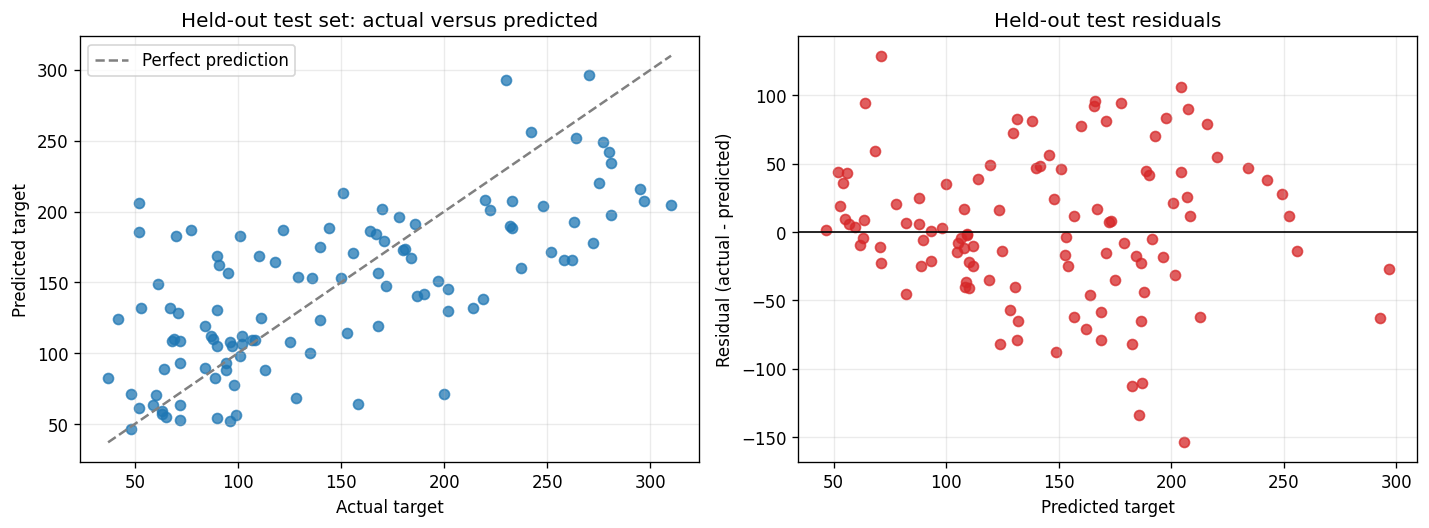

In [13]:
test_residuals = y_test_reg - y_pred_reg
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

lower, upper = min(y_test_reg.min(), y_pred_reg.min()), max(y_test_reg.max(), y_pred_reg.max())
axes[0].scatter(y_test_reg, y_pred_reg, alpha=0.75, color="#1f77b4")
axes[0].plot([lower, upper], [lower, upper], "--", color="gray", label="Perfect prediction")
axes[0].set(xlabel="Actual target", ylabel="Predicted target", title="Held-out test set: actual versus predicted")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].scatter(y_pred_reg, test_residuals, alpha=0.75, color="#d62728")
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set(xlabel="Predicted target", ylabel="Residual (actual - predicted)", title="Held-out test residuals")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()


The regression metrics and plots describe prediction error only for this held-out split. The residual plot can suggest patterns worth investigating, but it cannot by itself prove a model assumption or establish usefulness outside this dataset.


## 8. Comparison, limitations, and conclusion

The PDF reference cases demonstrate how metrics are calculated when outcomes and predictions are already supplied. The scikit-learn experiments demonstrate the additional workflow required to evaluate a fitted model honestly: inspect data, split before fitting, fit preprocessing on training data only, and evaluate exactly once on held-out data.

### Limitations

- The PDF examples are small educational calculations, not datasets for model training or generalization.
- The breast-cancer and diabetes datasets are separate teaching datasets; neither is evidence for clinical deployment.
- The results depend on one reproducible split and simple baseline models. They are not claims of optimal performance.
- Metrics summarize error; they do not establish fairness, causality, calibration, or practical suitability.

### Conclusion

Several metrics and diagnostic plots provide a more useful evaluation than a single score. Separating reference arithmetic from held-out model evaluation makes the conclusions traceable, reproducible, and appropriately limited.


## References

1. *Classification Model Evaluation: Case Study Solutions*. Supplied educational reference PDF.
2. *Predicting Patient Length of Stay in Days*. Supplied educational reference PDF.
3. scikit-learn developers. Built-in `load_breast_cancer` and `load_diabetes` datasets, accessed through scikit-learn.
